# E08 · Weight averaging: model soup, EMA, SWA and training less (variants a, b)

Does a model generalise better to the Kaggle images when its weights are **averaged**, or when it is **trained for fewer
epochs**? Both keep the model closer to flat, general solutions. All variants use the `E06c` setup (EfficientNet-B0,
`hist_split`, contrast augmentation, round-2 pseudo-labels 2×) and AdaBN balanced at the end.

| Variant | What it is |
|---|---|
| **E08a** · model soup | **no training:** the weights of E06b and E06c (and of E06a, E06b, E06c) averaged into one model (Wortsman et al. 2022). Possible because they start from the same ImageNet weights, with the same architecture, normalisation and seed |
| **E08b** · one run, several models | E06c setup trained for all 20 epochs (no early stopping), keeping: the weights after epochs **5, 8, 12** (training less), the **final** weights, an **EMA** (exponential moving average of the weights, decay 0.999 ≈ last 5 epochs) and **SWA** (plain average after epochs 16–20) |

Averaged weights (soups, EMA, SWA) get their BatchNorm statistics re-measured on EuroSAT training images before the
internal test (averaged statistics don't belong to the averaged weights); every model gets AdaBN balanced on Kaggle.

**E08b pseudo-labels:** selected as in E06c, but with `find_run` fixed: the "E06a without AdaBN agrees" rule really
applies, so the set is slightly smaller (2,300 images). Compare E08b's variants with its own `final`, not with E06c.

Reference: E06c + AdaBN, **71.50%**. **Train or load:** E08a needs no training; `LOAD_RUNS` works as in the other
notebooks for E08b (about 30 minutes to train).

## 1 · Setup and data

In [1]:
import json
import sys
from dataclasses import asdict, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS
from src.experiment import (add_pseudo_labels, adabn_balanced, class_mix, compare_variants, find_run,
                            finish_run, kaggle_monitor, load_experiment_data, load_saved_model,
                            plot_class_mix, plot_variant_curves, pseudo_label_summary,
                            pseudo_labels_from_run, pseudo_labels_from_table, view_agreement)
from src.models import MEDIUM_TRACK_LIMIT, build_model
from src.plot_style import apply_style
from src.training import (Normalizer, TrainConfig, adapt_batchnorm, fit, load_run, new_run_dir,
                          predict_proba, predict_views, write_submission)
from src.utils import describe_device, get_device, seed_everything

apply_style()

# ---- Experiment settings ---------------------------------------------------------------
NOTEBOOK = "E08_weight_averaging"
REFERENCE = "adabn_balanced_pseudo_label_r2_x2_contrast_aug_hist_split_effb0"   # E06c + AdaBN, 71.50%
# E08a · model soup
MEMBERS = {
    "E06a": "pseudo_label_contrast_aug_hist_split_effb0",
    "E06b": "pseudo_label_r2_contrast_aug_hist_split_effb0",
    "E06c": "pseudo_label_r2_x2_contrast_aug_hist_split_effb0",
}
SOUPS = {"soup_e09_e10": ["E06b", "E06c"], "soup_e08_e09_e10": ["E06a", "E06b", "E06c"]}   # folder names from the old numbering
LOAD_SOUPS = True        # True = load the saved adapted soups; False = adapt again (new run folders)
N_BN_IMAGES = 8000       # EuroSAT training images for re-measuring BatchNorm statistics
# E08b · one training run, several models
LOAD_RUNS = {"E08b": "runs/2026-10-13_1935_ema_ckpt_pl_r2_x2_contrast_aug_hist_split_effb0"}   # None = train
LABEL_RUN = "adabn_balanced_pseudo_label_contrast_aug_hist_split_effb0"   # E06a + AdaBN
CHECK_RUN = "pseudo_label_contrast_aug_hist_split_effb0"                   # E06a without AdaBN
PL_PER_CLASS, PL_REPEAT = 250, 2
SNAPSHOT_EPOCHS = (5, 8, 12, 16, 17, 18, 19, 20)
EMA_DECAY = 0.999
SWA_EPOCHS = (16, 17, 18, 19, 20)
MODEL = "efficientnet_b0"
BANDS = list(TEST_BANDS)
SEED = 42
cfg = TrainConfig(epochs=20, batch_size=128, lr=1e-3, weight_decay=1e-4,
                  label_smoothing=0.1, patience=5, augment=True,
                  photometric={"contrast": (0.9, 1.5), "band_contrast": (0.9, 1.15),
                               "brightness": (0.93, 1.07), "p": 0.8})   # as in E04
cfg_b = replace(cfg, patience=99)    # all 20 epochs, so every checkpoint exists
# -----------------------------------------------------------------------------------------

seed_everything(SEED)
device = get_device()              # CUDA > Apple GPU (MPS) > CPU
print("Device:", describe_device(device))
results = {}                        # variant -> RunResult, compared at the end

data = load_experiment_data(BANDS, ["hist_split"], device)
print(data.summary())
bn_idx = torch.from_numpy(np.random.default_rng(SEED).choice(len(data.tr_images), N_BN_IMAGES, replace=False)).to(device)
ref_model, ref_norm, _ = load_run(find_run(REFERENCE), device)
views_ref = predict_views(ref_model, data.kg_images, ref_norm)
prob_ref = views_ref.mean(0)
del ref_model


def average(states):
    """Average of state_dicts: floating-point tensors averaged, integer counters from the first."""
    return {k: (torch.stack([s[k].float() for s in states]).mean(0).to(v.dtype) if v.dtype.is_floating_point
                else v.clone()) for k, v in states[0].items()}


def evaluate(model, normalizer, recalibrate: bool):
    """Internal test accuracy (after re-measuring BatchNorm on EuroSAT if ``recalibrate``)."""
    if recalibrate:
        torch.manual_seed(SEED)                      # batch order
        adapt_batchnorm(model, data.tr_images[bn_idx], normalizer)
    return float((predict_proba(model, data.te_images, normalizer).argmax(1) == data.y_te).mean())


def kaggle_row(test_acc, views, score=None):
    prob = views.mean(0)
    return {"internal test (%)": test_acc * 100, "confidence (%)": prob.max(1).mean() * 100,
            "view agreement (%)": view_agreement(views) * 100,
            "same class as E06c (%)": (prob.argmax(1) == prob_ref.argmax(1)).mean() * 100,
            "differs on E06c-uncertain (%)": (prob.argmax(1) != prob_ref.argmax(1))[prob_ref.max(1) < 0.6].mean() * 100,
            "Kaggle public (%)": score}

Device: Apple GPU (MPS)


train 18,900  val 4,050  internal test 4,050  Kaggle test 4,232


## 2 · E08a · Model soup

The members are close in weight space (relative distance about 0.08), a precondition for a working soup.

In [2]:
member_dirs = {k: find_run(v) for k, v in MEMBERS.items()}
states = {k: torch.load(d / "model.pt", map_location="cpu") for k, d in member_dirs.items()}

def weight_distance(a, b):
    keys = [k for k, v in states[a].items() if v.dtype.is_floating_point and "running" not in k]
    num = sum(((states[a][k] - states[b][k]) ** 2).sum() for k in keys)
    return float(torch.sqrt(num / sum((states[a][k] ** 2).sum() for k in keys)))

print("Relative distance between members' weights (0 = identical):")
for a, b in [("E06b", "E06c"), ("E06a", "E06c"), ("E06a", "E06b")]:
    print(f"  {a}-{b}: {weight_distance(a, b):.3f}")

soup_rows = {}
for name, members in SOUPS.items():
    model, normalizer, _ = load_run(member_dirs["E06c"], device)
    model.load_state_dict(average([states[m] for m in members]))
    test_acc = evaluate(model, normalizer, recalibrate=True)
    if LOAD_SOUPS:
        ada_dir = find_run(f"adabn_balanced_{name}_effb0")
        model, normalizer, _ = load_run(ada_dir, device)
    else:
        model, _ = adabn_balanced(model, normalizer, data, SEED)
        ada_dir = new_run_dir(f"adabn_balanced_{name}_effb0")
        torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, ada_dir / "model.pt")
        (ada_dir / "config.json").write_text(json.dumps({
            **json.loads((member_dirs["E06c"] / "config.json").read_text()), "run_name": ada_dir.name,
            "notebook": NOTEBOOK, "variant": "E08a", "method": "model soup + adabn_balanced",
            "description": f"model soup of {', '.join(members)} (weights averaged) + AdaBN balanced",
            "members": [str(member_dirs[m].relative_to(PROJECT_ROOT)) for m in members]}, indent=2))
    views = predict_views(model, data.kg_images, normalizer)
    if not LOAD_SOUPS:
        (ada_dir / "metrics.json").write_text(json.dumps({
            "internal_test_acc": test_acc, "kaggle_mean_confidence": float(views.mean(0).max(1).mean()),
            "kaggle_view_agreement": view_agreement(views),
            "kaggle_predicted_mix_pct": class_mix(views.mean(0)).round(2).to_dict(), "kaggle_public_score": None}, indent=2))
    write_submission(views.mean(0), data.test_ids, ada_dir / "submission.csv")
    score = json.loads((ada_dir / "metrics.json").read_text()).get("kaggle_public_score")
    soup_rows[f"E08a {' + '.join(members)}"] = kaggle_row(test_acc, views, None if score is None else score * 100)
    print(f"{name}: {ada_dir.relative_to(PROJECT_ROOT)}")
pd.DataFrame(soup_rows).T.round(2)

Relative distance between members' weights (0 = identical):
  E06b-E06c: 0.076
  E06a-E06c: 0.084
  E06a-E06b: 0.080


soup_e09_e10: runs/2026-10-13_1843_adabn_balanced_soup_e09_e10_effb0


soup_e08_e09_e10: runs/2026-10-13_1844_adabn_balanced_soup_e08_e09_e10_effb0


,internal test (%),confidence (%),view agreement (%),same class as E06c (%),differs on E06c-uncertain (%),Kaggle public (%)
E08a E06b + E06c,99.04,77.37,84.64,96.90,27.49,71.69
E08a E06a + E06b + E06c,98.91,56.96,83.81,95.72,34.15,NaN


## 3 · E08b · Training less and weight averaging within one run

One training run of the E06c setup; the snapshots are kept in memory during training and saved to
`variants/` in the run folder (weights not in Git).

In [3]:
pl_table, pl_idx = pseudo_labels_from_run(LABEL_RUN, CHECK_RUN, PL_PER_CLASS, data, device)
tr_images, tr_labels, _ = add_pseudo_labels(data, pl_table, pl_idx, repeat=PL_REPEAT)

if LOAD_RUNS["E08b"]:
    model, normalizer, history = load_saved_model(LOAD_RUNS["E08b"], device)
    best_state, snapshots = None, None
else:
    seed_everything(SEED)
    normalizer = Normalizer.fit(data.X_tr)
    model = build_model(MODEL, bands=BANDS, pretrained=True).to(device)
    snapshots = {}
    history, best_state = fit(model, tr_images, tr_labels, data.va_images, data.va_labels, normalizer, cfg_b,
                              monitor=kaggle_monitor(data, normalizer), snapshots=snapshots,
                              snapshot_epochs=SNAPSHOT_EPOCHS, ema_decay=EMA_DECAY)
del tr_images, tr_labels

results["E08b"] = finish_run(model, normalizer, history, best_state, data, variant="E08b", load_run=LOAD_RUNS["E08b"],
    device=device, seed=SEED, param_limit=MEDIUM_TRACK_LIMIT,
    config={"run_name": "ema_ckpt_pl_r2_x2_contrast_aug_hist_split_effb0",
            "description": "E06c setup, 20 epochs without early stopping, EMA + checkpoints", "notebook": NOTEBOOK,
            "variant": "E08b", "model": MODEL, "bands": BANDS, "corrections": ["hist_split"], "train": asdict(cfg_b),
            "split": "split_seed42", "pseudo_labels": {"label_run": LABEL_RUN, "check_run": CHECK_RUN,
            "per_class": PL_PER_CLASS, "repeat": PL_REPEAT, "n_images": int(len(pl_idx))},
            "ema_decay": EMA_DECAY, "snapshot_epochs": list(SNAPSHOT_EPOCHS)})

Pseudo-labelled Kaggle images: 2,300 of 4,232, used 2x (19.6% of the training set, 23,500 images)
Loaded runs/2026-10-13_1935_ema_ckpt_pl_r2_x2_contrast_aug_hist_split_effb0 (20 epochs): no training


E08b: internal test 98.77% · Kaggle confidence 85.2% (with AdaBN 82.2%) · 4,022,950 parameters
  run folders: runs/2026-10-13_1935_ema_ckpt_pl_r2_x2_contrast_aug_hist_split_effb0, runs/2026-10-13_1937_adabn_balanced_ema_ckpt_pl_r2_x2_contrast_aug_hist_split_effb0


In [4]:
run_dir = results["E08b"].run_dir
var_dir = run_dir / "variants"
var_dir.mkdir(exist_ok=True)
if snapshots is None:      # loaded run: weights saved earlier
    variant_states = {p.stem: torch.load(p, map_location="cpu") for p in sorted(var_dir.glob("*.pt"))}
else:
    variant_states = {f"epoch_{e}": snapshots[f"epoch_{e}"] for e in (5, 8, 12)}
    variant_states["final"] = {k: v.cpu() for k, v in best_state.items()}
    variant_states["ema"] = snapshots["ema"]
    variant_states["swa_16_20"] = average([snapshots[f"epoch_{e}"] for e in SWA_EPOCHS])
    for name, st in variant_states.items():
        torch.save(st, var_dir / f"{name}.pt")

order = ["epoch_5", "epoch_8", "epoch_12", "final", "ema", "swa_16_20"]
var_rows, var_preds = {}, {}
for name in order:
    m, norm, _ = load_run(run_dir, device)
    m.load_state_dict(variant_states[name])
    test_acc = evaluate(m, norm, recalibrate=name in ("ema", "swa_16_20"))
    torch.manual_seed(SEED)                          # AdaBN batch order
    m, _ = adabn_balanced(m, norm, data, SEED)
    views = predict_views(m, data.kg_images, norm)
    out = var_dir / name
    if snapshots is None and (out / "submission.csv").exists():
        # Loaded run: keep the saved files (the submitted ones). AdaBN is re-measured here, and the order of its
        # batches was not seeded originally, so a few labels can differ from the saved submission.
        saved = pd.read_csv(out / "submission.csv")["label"].values
        same = (np.array(CLASSES)[views.mean(0).argmax(1)] == saved).mean()
        print(f"{name}: recomputed labels match the saved submission on {same:.2%} of the images")
        score = json.loads((out / "metrics.json").read_text()).get("kaggle_public_score")
    else:
        out.mkdir(exist_ok=True)
        write_submission(views.mean(0), data.test_ids, out / "submission.csv")
        score = None
        (out / "metrics.json").write_text(json.dumps({
            "variant": name, "internal_test_acc": test_acc, "kaggle_mean_confidence": float(views.mean(0).max(1).mean()),
            "kaggle_view_agreement": view_agreement(views),
            "kaggle_predicted_mix_pct": class_mix(views.mean(0)).round(2).to_dict(), "kaggle_public_score": None}, indent=2))
    var_rows[f"E08b {name}"] = kaggle_row(test_acc, views, None if score is None else score * 100)
    var_preds[name] = views.mean(0).argmax(1)
table = pd.DataFrame(var_rows).T
table["same class as final (%)"] = [(var_preds[n] == var_preds["final"]).mean() * 100 for n in order]
table.round(2)

epoch_5: recomputed labels match the saved submission on 99.86% of the images


epoch_8: recomputed labels match the saved submission on 99.76% of the images


epoch_12: recomputed labels match the saved submission on 99.88% of the images


final: recomputed labels match the saved submission on 99.79% of the images


ema: recomputed labels match the saved submission on 99.98% of the images


swa_16_20: recomputed labels match the saved submission on 99.86% of the images


,internal test (%),confidence (%),view agreement (%),same class as E06c (%),differs on E06c-uncertain (%),Kaggle public (%),same class as final (%)
E08b epoch_5,97.43,78.49,79.66,90.31,49.00,NaN,90.52
E08b epoch_8,98.07,80.57,81.00,92.91,46.12,NaN,93.50
E08b epoch_12,98.52,81.88,83.27,93.34,45.68,NaN,95.65
E08b final,98.77,82.22,84.03,94.64,37.69,NaN,100.00
E08b ema,98.77,81.50,84.31,94.80,37.25,71.55,98.65
E08b swa_16_20,98.77,82.31,83.84,94.47,39.47,NaN,99.01


## 4 · Comparison

In [5]:
ref_test_acc = json.loads((member_dirs["E06c"] / "metrics.json").read_text())["internal_test_acc"]
ref_score = json.loads((find_run(REFERENCE) / "metrics.json").read_text())["kaggle_public_score"] * 100
pd.concat([pd.DataFrame({"E06c + AdaBN (reference)": kaggle_row(ref_test_acc, views_ref, ref_score)}).T,
           pd.DataFrame(soup_rows).T, table.drop(columns="same class as final (%)")]).round(2)

,internal test (%),confidence (%),view agreement (%),same class as E06c (%),differs on E06c-uncertain (%),Kaggle public (%)
E06c + AdaBN (reference),98.94,81.59,84.22,100.00,0.00,71.50
E08a E06b + E06c,99.04,77.37,84.64,96.90,27.49,71.69
E08a E06a + E06b + E06c,98.91,56.96,83.81,95.72,34.15,NaN
E08b epoch_5,97.43,78.49,79.66,90.31,49.00,NaN
E08b epoch_8,98.07,80.57,81.00,92.91,46.12,NaN
E08b epoch_12,98.52,81.88,83.27,93.34,45.68,NaN
E08b final,98.77,82.22,84.03,94.64,37.69,NaN
E08b ema,98.77,81.50,84.31,94.80,37.25,71.55
E08b swa_16_20,98.77,82.31,83.84,94.47,39.47,NaN


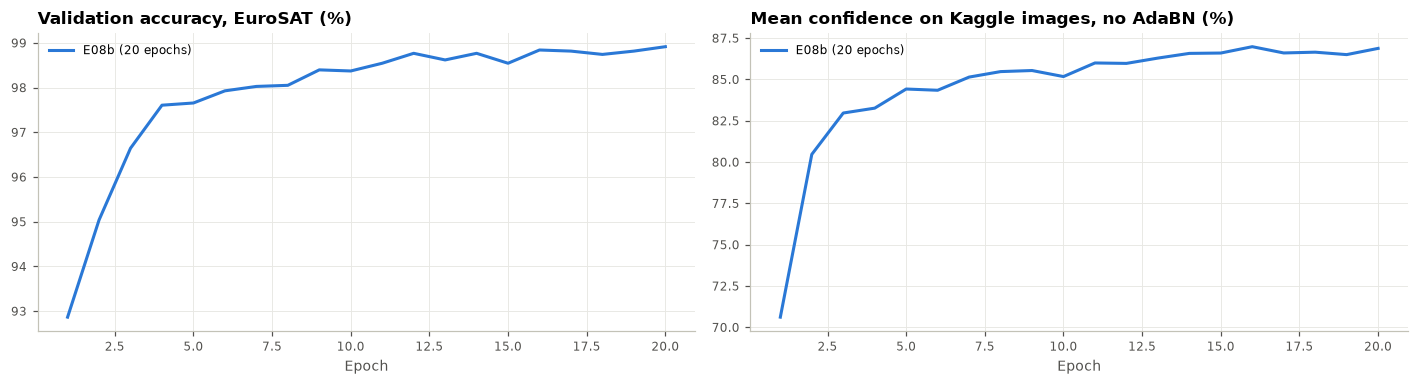

In [6]:
plot_variant_curves({"E08b (20 epochs)": results["E08b"]})

## 5 · Conclusion

| Model | Internal test | View agreement | Same class as E06c | Kaggle public |
|---|---|---|---|---|
| E06c + AdaBN (reference) | 98.94% | 84.2% | – | 71.50% |
| **E08a soup E06b + E06c** | **99.0%** | **84.6%** | 96.9% | **71.69%** |
| E08a soup E06a + E06b + E06c | 98.9% | 83.8% | 95.7% | not submitted |
| E08b epoch 5 / 8 / 12 | 97.4 / 98.1 / 98.5% | 79.6 / 80.9 / 83.3% | 90–93% | – |
| E08b final | 98.8% | 84.0% | 94.7% | – |
| E08b EMA | 98.8% | 84.4% | 94.8% | 71.55% |
| E08b SWA 16–20 | 98.8% | 83.9% | 94.5% | – |

- **Averaging the weights of independent runs works:** the members are close (relative distance 0.08) and the soups are
  as accurate on EuroSAT as their members, at no training cost and with the same 4.02M parameters.
- **The E06b + E06c soup is the best model so far** (71.69%), and the best on EuroSAT and view agreement. The gain over
  E06c (+0.2) is within public-leaderboard noise; the main argument for it is robustness: averaging two runs evens out
  run-specific chance (batch order, augmentation, pseudo-label noise).
- **Training less does not help:** every earlier checkpoint is worse on EuroSAT *and* less stable on Kaggle. With
  pseudo-labelled Kaggle images in training, longer training also means more learning on the target domain.
- **Averaging within one run changes little:** EMA and SWA agree with the final weights on about 98.7% of the images;
  EMA scored 71.55%, the level of E06c.
- **Confidence is not comparable for soups:** averaged weights give flatter probabilities (57% mean confidence for the
  three-member soup) without being less accurate.

**Lesson:** for robustness, average independent runs (soup or ensemble) rather than points of one run. **Suggested final
Kaggle selection:** E08a soup E06b + E06c and E06c + AdaBN.